# 🎯 Task-Specific EDA: Named Entity Recognition & Token Classification
## BIO Tag Distribution, Entity Span Lengths, Class Imbalance & Sequence Validity
**Kit:** `01_NLU/03_token_classification_ner` | **Standard:** GEMASTIK XIX 2026 & Kaggle NLP  
**Focus:** Token sequence labeling, PII data detection, legal entity extraction, BIO scheme integrity.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

train_path = '../demo_data/train.csv'
test_path  = '../demo_data/test.csv'

train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)

print(f"Train sentences: {len(train_df)} | Test sentences: {len(test_df)}")
train_df.head()


Train sentences: 12 | Test sentences: 4


,document_id,full_text,tokens,labels
0,Doc_001,Halo nama saya Budi Santoso dan email saya ada...,"[""Halo"", ""nama"", ""saya"", ""Budi"", ""Santoso"", ""d...","[""O"", ""O"", ""O"", ""B-NAME"", ""I-NAME"", ""O"", ""O"", ..."
1,Doc_002,Please contact Dr. Sarah Connor via sarah.c@cy...,"[""Please"", ""contact"", ""Dr."", ""Sarah"", ""Connor""...","[""O"", ""O"", ""O"", ""B-NAME"", ""I-NAME"", ""O"", ""B-EM..."
2,Doc_003,Nama mahasiswa adalah Siti Rahma dan nomor tel...,"[""Nama"", ""mahasiswa"", ""adalah"", ""Siti"", ""Rahma...","[""O"", ""O"", ""O"", ""B-NAME"", ""I-NAME"", ""O"", ""O"", ..."
3,Doc_004,The participant John Doe registered under emai...,"[""The"", ""participant"", ""John"", ""Doe"", ""registe...","[""O"", ""O"", ""B-NAME"", ""I-NAME"", ""O"", ""O"", ""O"", ..."
4,Doc_005,Mahasiswa Ahmad Fauzi menghubungi sekretariat ...,"[""Mahasiswa"", ""Ahmad"", ""Fauzi"", ""menghubungi"",...","[""O"", ""B-NAME"", ""I-NAME"", ""O"", ""O"", ""O"", ""O"", ..."


In [2]:
import ast

TAG_COL = 'labels' if 'labels' in train_df.columns else 'tags'
all_tags = []
for tags_val in train_df[TAG_COL].dropna():
    if isinstance(tags_val, str) and tags_val.strip().startswith('['):
        try:
            all_tags.extend(ast.literal_eval(tags_val))
        except Exception:
            all_tags.extend(tags_val.split())
    else:
        all_tags.extend(str(tags_val).split())

tag_counts = pd.Series(all_tags).value_counts()
total_tokens = len(all_tags)
o_tokens = tag_counts.get('O', 0)
entity_tokens = total_tokens - o_tokens

print(f"Detected Tag Column   : '{TAG_COL}'")
print(f"Total Tokens Analyzed : {total_tokens:,}")
print(f"Background 'O' Tokens : {o_tokens:,} ({o_tokens / total_tokens * 100:.2f}%)")
print(f"Target Entity Tokens  : {entity_tokens:,} ({entity_tokens / total_tokens * 100:.2f}%)")
print(f"Token Imbalance Ratio : {o_tokens / (entity_tokens + 1e-5):.1f}:1")
print("\nTop Token Tags Breakdown:\n", tag_counts)


Detected Tag Column   : 'labels'
Total Tokens Analyzed : 118
Background 'O' Tokens : 83 (70.34%)
Target Entity Tokens  : 35 (29.66%)
Token Imbalance Ratio : 2.4:1

Top Token Tags Breakdown:
 O          83
B-NAME     12
I-NAME     12
B-EMAIL     7
B-PHONE     4
Name: count, dtype: int64


C:\Users\yasse\AppData\Local\Temp\ipykernel_41436\3054474301.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=entity_tags.index, y=entity_tags.values, palette='viridis')


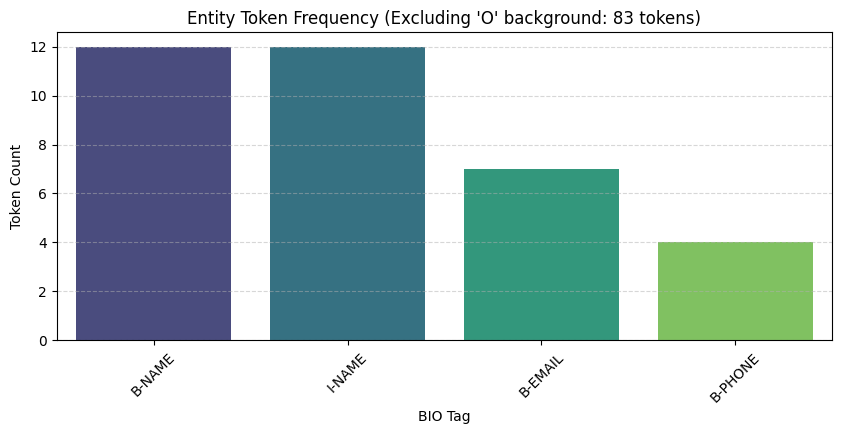

In [3]:
entity_tags = tag_counts[tag_counts.index != 'O']

plt.figure(figsize=(10, 4))
sns.barplot(x=entity_tags.index, y=entity_tags.values, palette='viridis')
plt.title(f"Entity Token Frequency (Excluding 'O' background: {o_tokens} tokens)")
plt.xlabel("BIO Tag")
plt.ylabel("Token Count")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


In [4]:
# Check for invalid BIO transitions: e.g. O -> I-Tag without preceding B-Tag
invalid_transitions = 0
total_transitions = 0

for tags_val in train_df[TAG_COL].dropna():
    if isinstance(tags_val, str) and tags_val.strip().startswith('['):
        try:
            tokens = ast.literal_eval(tags_val)
        except Exception:
            tokens = tags_val.split()
    else:
        tokens = str(tags_val).split()

    prev = 'O'
    for tag in tokens:
        total_transitions += 1
        if tag.startswith('I-'):
            expected_prefix = tag[2:]
            if prev != f'B-{expected_prefix}' and prev != f'I-{expected_prefix}':
                invalid_transitions += 1
        prev = tag

print(f"Total Transitions Checked : {total_transitions:,}")
print(f"Invalid BIO Transitions   : {invalid_transitions}")
if invalid_transitions == 0:
    print("✅ INTEGRITY CHECK PASSED: 100% compliant BIO transitions in ground truth.")
else:
    print(f"⚠️ INTEGRITY WARNING: Found {invalid_transitions} illegal BIO transitions; apply sequence repair rule post-processing.")


Total Transitions Checked : 118
Invalid BIO Transitions   : 0
✅ INTEGRITY CHECK PASSED: 100% compliant BIO transitions in ground truth.


### 📋 Master Decision Matrix (Token Classification / NER):
| Diagnostic Signal | Finding | Recommended Strategy |
| :--- | :--- | :--- |
| **Token Imbalance** | $> 90\%$ 'O' tokens | Apply CrossEntropy with ignored index `-100` on padding + subwords, or class-weighted loss. |
| **Subword Alignment** | Subwords split words | Label only the first subword with the entity tag; label trailing subwords with `-100` (or replicate tag). |
| **Illegal Transitions** | `O` $\to$ `I-*` transitions | Apply Viterbi decoding / rule-based BIO repair to convert orphan `I-*` to `B-*`. |
| **Evaluation Metric** | Seqeval Micro/Macro F1 | Evaluate strictly on full entity spans (exact match), not unweighted token accuracy. |
